# 01 - Exploratory Data Analysis

This notebook reviews the training and blind test data before modeling. It covers:
1. Data quality
2. Shape of the feature and target distributions
3. Which features carry signal
4. Correlation between features
5. Shape of the feature-target relationships and a linear baseline

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.options.display.float_format = "{:.3f}".format

train = pd.read_csv("../data/training_data.csv")
blind = pd.read_csv("../data/blind_test_data.csv")

FEATURES = [c for c in train.columns if c.startswith("feature_")]
TARGET = "target"
N = len(train)

train.shape, blind.shape

((800, 21), (200, 20))

## 1. Data quality

In [ ]:
print("nulls train:", train.isna().sum().sum())
print("nulls blind:", blind.isna().sum().sum())
print("dtypes:", train.dtypes.unique())
print("columns only in train:", set(train.columns) - set(blind.columns))

nulls train: 0
nulls blind: 0
dtypes: [dtype('float64')]
columns only in train: {'target'}


Both datasets are complete: there are no missing values and every column is numeric (float64).
The blind test set contains the same 20 features as the training set, without the target column.

## 2. Distributions
### Features

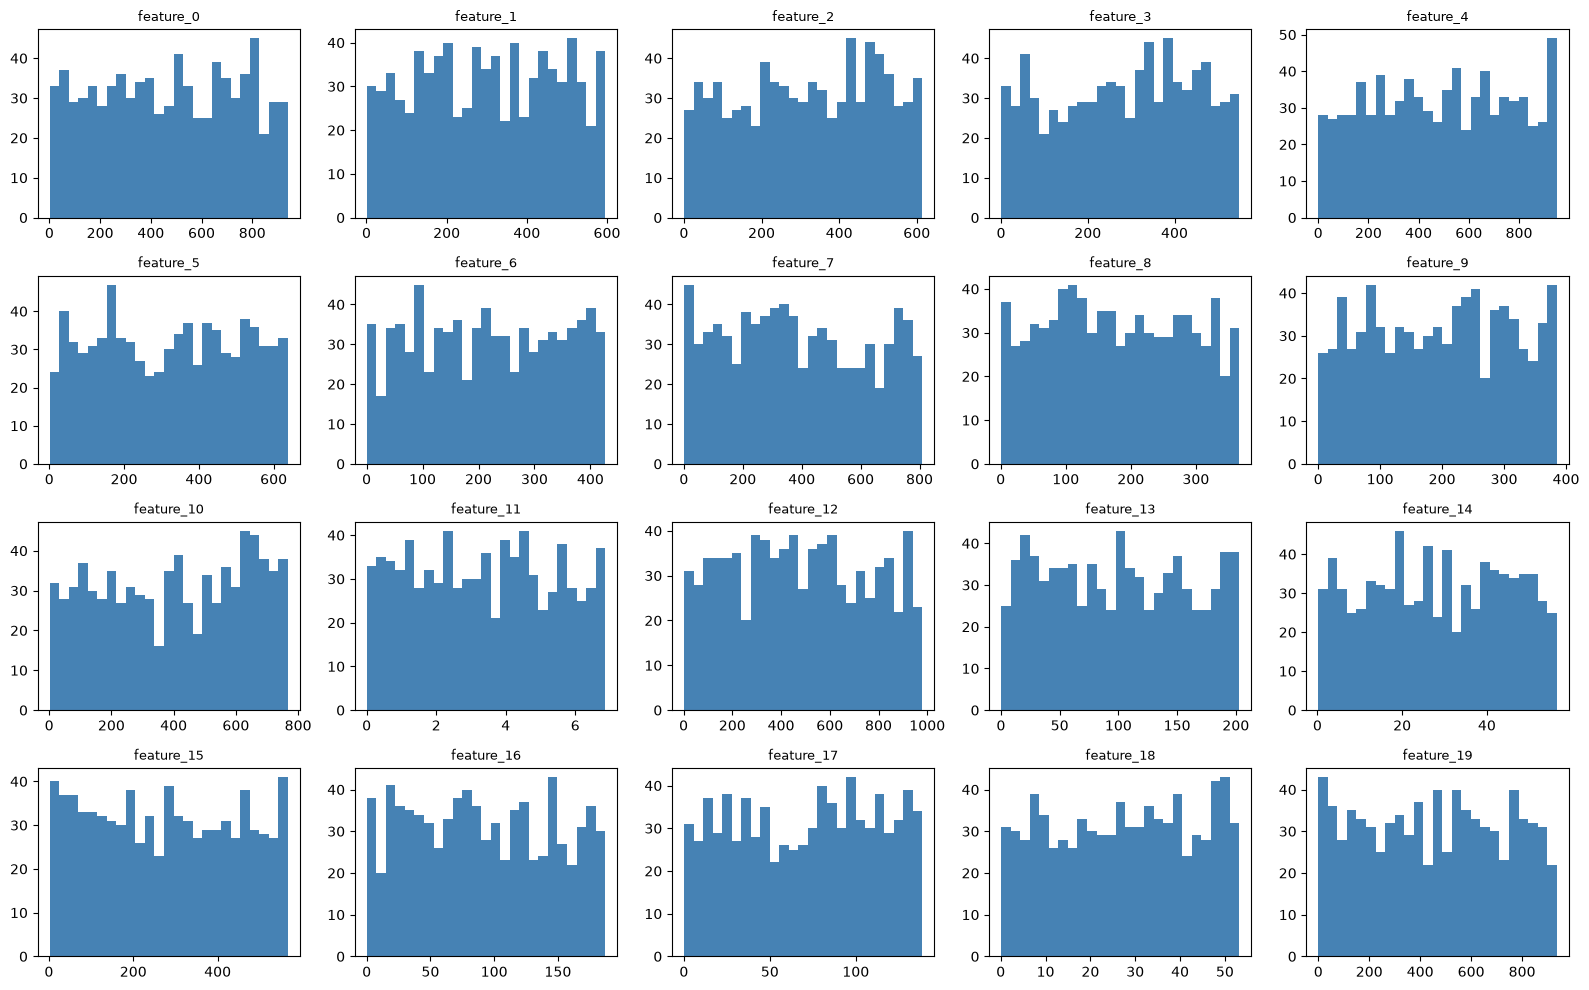

In [ ]:
fig, axes = plt.subplots(4, 5, figsize=(16, 10))
for ax, f in zip(axes.ravel(), FEATURES):
    ax.hist(train[f], bins=25, color="steelblue")
    ax.set_title(f, fontsize=9)
plt.tight_layout()

The histograms are flat. For a uniform distribution, range / standard deviation equals
sqrt(12) = 3.46, which gives a simple numeric check on top of the plots.

In [ ]:
ranges = pd.DataFrame({
    "min":
    train[FEATURES].min(),
    "max":
    train[FEATURES].max(),
    "range_over_std":
    (train[FEATURES].max() - train[FEATURES].min()) / train[FEATURES].std(),
})
print("range/std between", round(ranges["range_over_std"].min(), 2), "and",
      round(ranges["range_over_std"].max(), 2))
ranges.sort_values("max")

range/std between 3.35 and 3.54


,min,max,range_over_std
feature_11,0.004,6.859,3.451
feature_18,0.102,53.255,3.427
feature_14,0.222,56.467,3.492
feature_17,0.073,138.675,3.415
feature_16,0.094,187.041,3.465
feature_13,0.194,203.122,3.431
feature_8,0.728,367.085,3.521
feature_9,0.264,384.919,3.464
feature_6,0.402,426.308,3.444
feature_3,0.309,549.896,3.485


- Every feature has a range/std ratio between 3.35 and 3.54, consistent with a uniform distribution.
  There are no tails and no extreme values.
- Each feature lives on its own scale (feature_11 tops at ~7, feature_12 at ~980).
  Linear models will need standardization; tree-based models are unaffected.

### Target
The Q-Q plot compares the target quantiles against a normal distribution: points on the
diagonal mean normal behaviour, and bends at the ends reveal heavier or lighter tails.

skew: -0.04 | excess kurtosis: -0.54


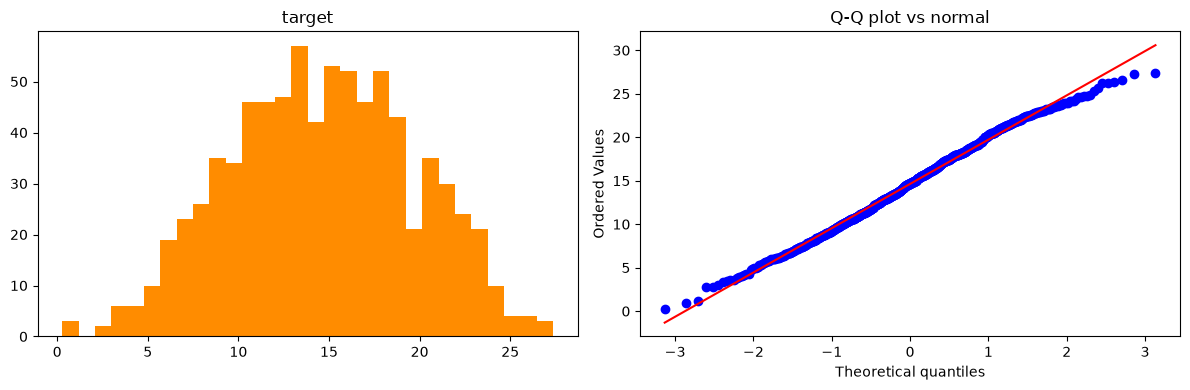

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train[TARGET], bins=30, color="darkorange")
axes[0].set_title("target")
stats.probplot(train[TARGET], dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot vs normal")
plt.tight_layout()

print("skew:", round(train[TARGET].skew(), 3), "| excess kurtosis:",
      round(train[TARGET].kurt(), 3))

The target is symmetric (skew -0.04) and ranges from 0.3 to 27.4. Its tails are lighter than a normal
distribution (excess kurtosis -0.54, visible as the flattened ends of the Q-Q plot), so there are no
extreme target values. No transformation is needed.

## 3. Signal: which features matter
### Correlation with the target
Pearson correlation measures how well a straight line describes the relationship between each feature
and the target, from 0 (no relationship) to 1 (perfect line).

,pearson
feature_2,0.552
feature_13,0.405
feature_9,0.362
feature_11,0.323
feature_4,-0.063
feature_18,0.060


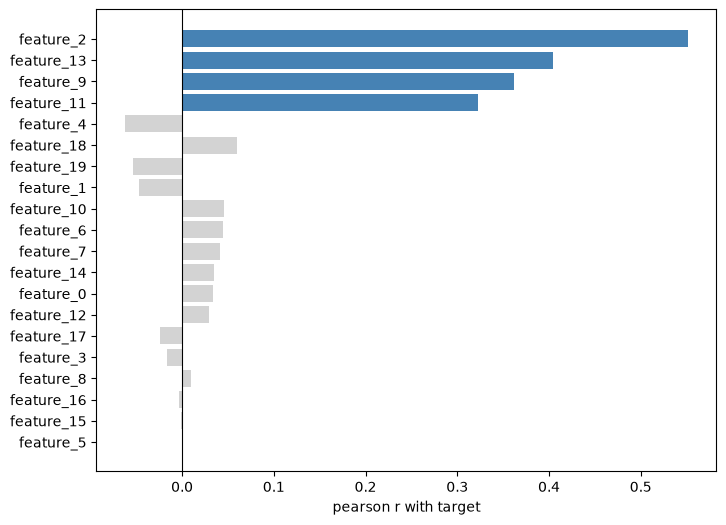

In [ ]:
pearson = train[FEATURES].corrwith(train[TARGET])
order = pearson.abs().sort_values().index

fig, ax = plt.subplots(figsize=(8, 6))
colors = ["steelblue" if abs(pearson[f]) > 0.1 else "lightgray" for f in order]
ax.barh(order, pearson[order], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("pearson r with target")
pearson.sort_values(key=abs, ascending=False).head(6).to_frame("pearson")

Four features show a clear positive correlation with the target: feature_2 (0.55), feature_13 (0.40),
feature_9 (0.36) and feature_11 (0.32). The remaining sixteen stay below 0.07 in absolute value,
which is the level of correlation that random noise alone produces with 800 rows.

### Three measures of dependency
Pearson only detects straight-line relationships. Spearman detects any monotonic relationship,
and mutual information detects any kind of dependency, including curves that go up and down.
Comparing the three shows whether a feature is being missed because its relationship is not linear.

,pearson,spearman,mutual_info
feature_2,0.552,0.543,0.184
feature_13,0.405,0.402,0.129
feature_16,0.004,0.008,0.063
feature_9,0.362,0.368,0.053
feature_3,0.017,0.019,0.037
feature_18,0.060,0.071,0.029
feature_11,0.323,0.317,0.027
feature_5,0.000,0.006,0.025


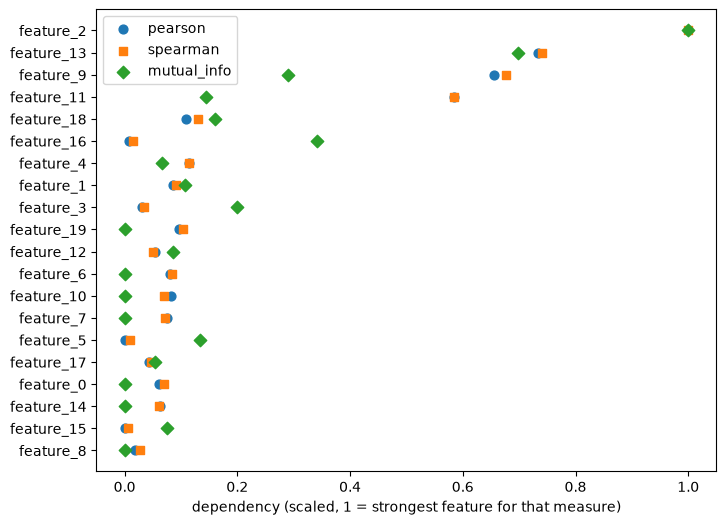

In [ ]:
from sklearn.feature_selection import mutual_info_regression

dep = pd.DataFrame(
    {
        "pearson":
        pearson.abs(),
        "spearman":
        train[FEATURES].corrwith(train[TARGET], method="spearman").abs(),
        "mutual_info":
        mutual_info_regression(train[FEATURES], train[TARGET], random_state=0),
    },
    index=FEATURES)

# scale each measure to [0, 1] so they fit on one axis
dep_scaled = dep / dep.max()
dep_scaled = dep_scaled.loc[dep_scaled.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(8, 6))
for col, marker in zip(dep_scaled.columns, ["o", "s", "D"]):
    ax.scatter(dep_scaled[col],
               dep_scaled.index,
               marker=marker,
               label=col,
               s=40)
ax.set_xlabel("dependency (scaled, 1 = strongest feature for that measure)")
ax.legend()
dep.sort_values("mutual_info", ascending=False).head(8)

- Pearson and Spearman agree on every feature, so none of the relationships is monotonic but non-linear
  in a way that Pearson would miss.
- Mutual information also ranks feature_2 and feature_13 at the top, but it is a noisier estimate with
  800 rows: it scores feature_11 low despite its clear correlation, and it assigns small non-zero values
  to features that Pearson rates near zero (feature_16, feature_3, feature_18). Those small values may be
  noise; the modeling stage tests every feature directly with permutation importance.

## 4. Correlation between features
The matrix shows the correlation of every pair of columns, with the target added as the last row.
Only the lower half is drawn because the matrix is symmetric (feature_1 vs feature_2 is the same
as feature_2 vs feature_1).

max |corr| between two features: 0.101


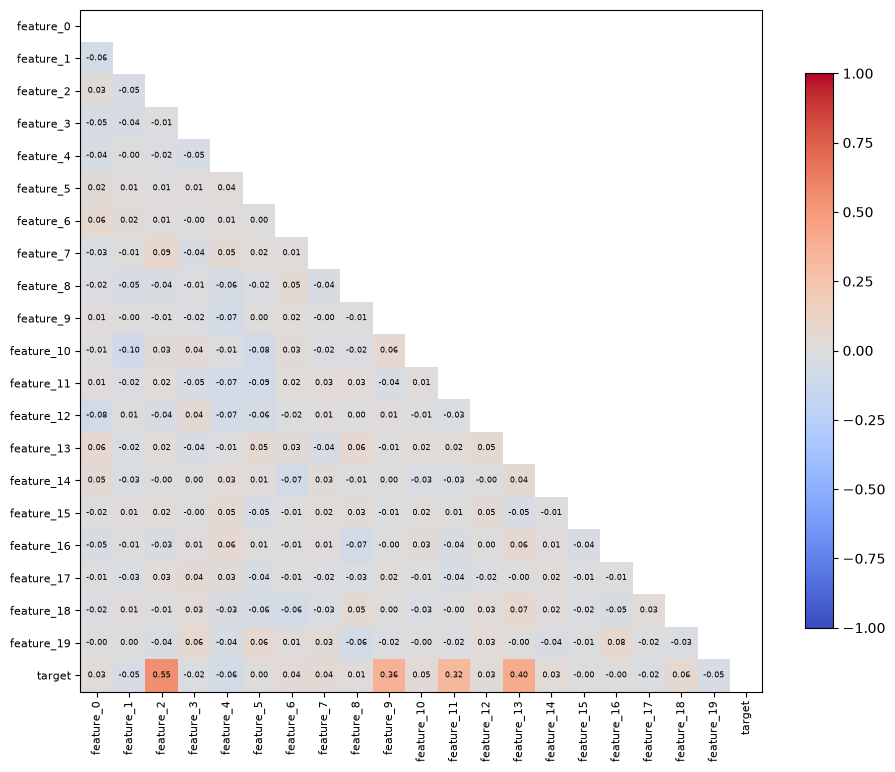

In [ ]:
cols = FEATURES + [TARGET]
corr = train[cols].corr()
upper = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr.mask(upper), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(cols)), cols, fontsize=8)
for i in range(len(cols)):
    for j in range(i):
        ax.text(j,
                i,
                f"{corr.iloc[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=5.5)
fig.colorbar(im, shrink=0.8)

between = corr.loc[FEATURES,
                   FEATURES].where(~np.eye(len(FEATURES), dtype=bool)).abs()
print("max |corr| between two features:", round(between.max().max(), 3))

Every cell between two features is close to zero (white), with a maximum absolute correlation of 0.10.
The features are independent of each other, so multicollinearity is not a concern and each one
contributes its own information. The only colored cells are in the target row, for the same four
features identified in section 3.

## 5. Shape of the relationships
Each panel shows the raw points and the average target within ten equal-size bins of the feature.
The binned average removes the noise and makes the shape of the relationship visible.

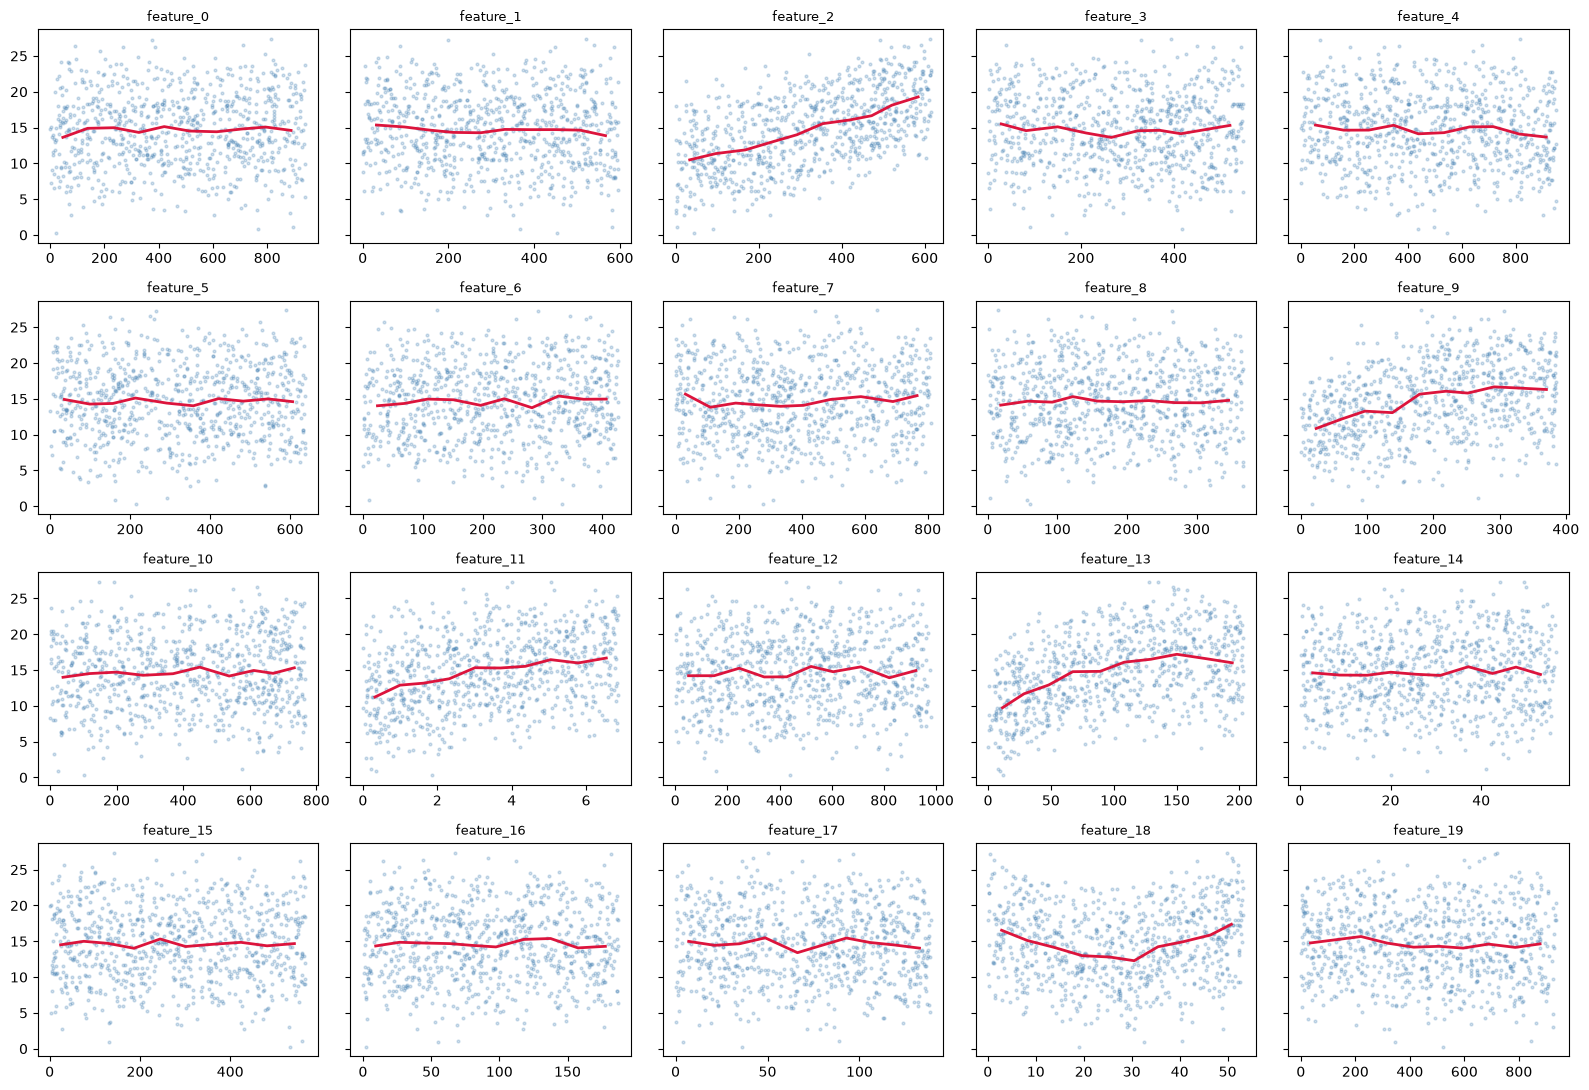

In [ ]:
def binned_mean(x, y, bins=10):
    groups = pd.qcut(x, bins)
    return x.groupby(groups,
                     observed=True).mean(), y.groupby(groups,
                                                      observed=True).mean()


fig, axes = plt.subplots(4, 5, figsize=(16, 11), sharey=True)
for ax, f in zip(axes.ravel(), FEATURES):
    ax.scatter(train[f], train[TARGET], s=4, alpha=0.25, color="steelblue")
    bx, by = binned_mean(train[f], train[TARGET])
    ax.plot(bx, by, color="crimson", lw=2)
    ax.set_title(f, fontsize=9)
plt.tight_layout()

- feature_2 and feature_11 increase steadily with the target.
- feature_13 and feature_9 increase and then flatten out.
- feature_18 has a curved pattern, with a higher target at both ends of its range.
- The remaining features show a flat trend.

A cross-validated linear regression measures how far a straight-line model can go.

In [ ]:
# linear baseline, 5-fold CV
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

rmse = -cross_val_score(LinearRegression(),
                        train[FEATURES],
                        train[TARGET],
                        cv=5,
                        scoring="neg_root_mean_squared_error")
print(f"linear regression CV RMSE: {rmse.mean():.3f} (+/- {rmse.std():.3f})")
print(
    f"target std (= RMSE of always predicting the mean): {train[TARGET].std():.3f}"
)

linear regression CV RMSE: 2.870 (+/- 0.089)
target std (= RMSE of always predicting the mean): 5.090


The linear regression reaches a cross-validated RMSE of 2.87, compared with 5.09 when always
predicting the mean. It explains roughly two thirds of the target variance; the curved patterns
above account for part of what remains. Non-linear models such as tree ensembles are therefore
included in the modeling stage.

## Conclusions
- The data is clean: no missing values, all numeric, uniform features on very different scales.
- Four features have a clear linear correlation with the target; the other sixteen are at noise level.
- The features are independent of each other (maximum pairwise correlation of 0.10).
- Some relationships are curved, so a linear model (RMSE 2.87) leaves structure unexplained and
  non-linear models are worth testing.